<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [NBA Basketball Data](https://github.com/Query-farm/vgi-nba)

Standings, scores, schedules, box scores, play-by-play, and player and team stats.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-nba/blob/main/notebooks/02_reconcile_games_events_and_players.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-nba/blob/main/notebooks/README.md)


## One score, three levels of detail

**When a late-period filter changes the events we inspect, which totals must stay fixed?** Reconcile one scoreboard game per schema with player box-score sums and the event feed, then separate selected scoring from whole-game scoring. These deliberately compressed scoring-only miniatures are not plausible full league games.

**Entirely synthetic local API scenario.** All people, teams, identifiers and
observations below are fictional. Three league schemas exercise the real released
worker's parsers; these are not NBA, WNBA or G League records, rankings or performance
comparisons. The first notebook separately preserves a tiny genuine recorded response.
The helper only serves declared JSON envelopes, with exact request audits; all
joins, measures and selections remain visible SQL. Identical numeric IDs deliberately
appear in different schemas, so **league plus ID** is the join key.

### Choose one local rule

`MIN_PERIOD` is an integer 1–4, inclusive. The default, 4, inspects fourth-period scoring; the experiment, 1, includes every period. The full scoreboard and box-score totals remain fixed.

In [1]:
MIN_PERIOD = 4

In [2]:
import importlib.metadata

try:
    _shared_version = importlib.metadata.version("vgi-example-notebooks")
except importlib.metadata.PackageNotFoundError:
    _shared_version = None
if _shared_version != "0.3.47":
    %pip -q install "vgi-example-notebooks @ git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.47"
from vgi_notebooks import check_runtime
from vgi_notebooks.bootstrap import prepare

check_runtime()
_companion_directory = prepare("nba")

In [3]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme
from nba_examples import NBAExample

if type(MIN_PERIOD) is not int or not 1 <= MIN_PERIOD <= 4:
    raise ValueError("MIN_PERIOD must be an integer from 1 through 4")
source = NBAExample("synthetic", "games")
theme()
session = connect(globals())
SOURCE = "Synthetic miniature · fictional inputs · NBA worker v0.2.0"
LEAGUE_LABELS = {"nba": "NBA", "wnba": "WNBA", "gleague": "G League"}

### Attach the released worker

The tag owns worker dependencies inside an isolated Python 3.13 environment.
Shared base tooling preserves the notebook kernel and initializes UTC plus an empty
temporary SQL-secret store with persistence disabled. First use requires Git/network
for packages and the VGI extension; these synthetic examples contact only loopback
for data. No live dataset is downloaded or substituted.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'nba' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-nba@v0.2.0 vgi-nba');

,Success


### Materialize three grains before joining

`scoreboard` has one game row, `box_score` has one player-game row, and
`play_by_play` has one event row. Fetch each once per league. The ten-digit text
IDs retain their leading league digit. A box-score sum must group by league and
game before joining the scoreboard; otherwise the game score repeats per player.

In [5]:
%%sql
CREATE TABLE boards_nba AS SELECT * FROM nba.nba.scoreboard(DATE '2025-10-21');
CREATE TABLE boards_wnba AS SELECT * FROM nba.wnba.scoreboard(DATE '2025-10-21');
CREATE TABLE boards_gleague AS SELECT * FROM nba.gleague.scoreboard(DATE '2025-10-21');
CREATE TABLE boards AS SELECT 'nba' AS league,* FROM boards_nba UNION ALL SELECT 'wnba' AS league,* FROM boards_wnba UNION ALL SELECT 'gleague' AS league,* FROM boards_gleague;
CREATE TABLE boxes_nba AS SELECT * FROM nba.nba.box_score('0022500001');
CREATE TABLE boxes_wnba AS SELECT * FROM nba.wnba.box_score('1022500001');
CREATE TABLE boxes_gleague AS SELECT * FROM nba.gleague.box_score('2022500001');
CREATE TABLE boxes AS SELECT 'nba' AS league,* FROM boxes_nba UNION ALL SELECT 'wnba' AS league,* FROM boxes_wnba UNION ALL SELECT 'gleague' AS league,* FROM boxes_gleague;
CREATE TABLE events_nba AS SELECT * FROM nba.nba.play_by_play('0022500001');
CREATE TABLE events_wnba AS SELECT * FROM nba.wnba.play_by_play('1022500001');
CREATE TABLE events_gleague AS SELECT * FROM nba.gleague.play_by_play('2022500001');
CREATE TABLE events AS SELECT 'nba' AS league,* FROM events_nba UNION ALL SELECT 'wnba' AS league,* FROM events_wnba UNION ALL SELECT 'gleague' AS league,* FROM events_gleague;

,Count


In [6]:
%%sql game_audit <<
WITH box_totals AS (
 SELECT league,game_id,sum(points) FILTER(WHERE is_home) AS home_box,
 sum(points) FILTER(WHERE NOT is_home) AS away_box FROM boxes GROUP BY ALL
), final_event AS (
 SELECT league,game_id,home_score AS home_event,away_score AS away_event FROM events
 QUALIFY row_number() OVER(PARTITION BY league,game_id ORDER BY action_id DESC)=1
)
SELECT b.league,b.game_id,b.home_team_tricode,b.away_team_tricode,b.home_score,b.away_score,
 x.home_box,x.away_box,e.home_event,e.away_event
FROM boards b JOIN box_totals x USING(league,game_id) JOIN final_event e USING(league,game_id)
ORDER BY league;

In [7]:
display(game_audit)
prose(
    f"All **{len(game_audit)} synthetic games** retain one scoreboard row. "
    "Each home/away total can now be compared with a player sum and the final event score "
    "without multiplying the scoreboard grain."
)

,league,game_id,home_team_tricode,away_team_tricode,home_score,away_score,home_box,away_box,home_event,away_event
0,gleague,2022500001,AAA,BBB,9,5,9.0,5.0,9,5
1,nba,0022500001,AAA,BBB,9,6,9.0,6.0,9,6
2,wnba,1022500001,AAA,BBB,10,5,10.0,5.0,10,5


All **3 synthetic games** retain one scoreboard row. Each home/away total can now be compared with a player sum and the final event score without multiplying the scoreboard grain.

### Use event IDs for sequence, then filter contributions

The last non-scoring event repeats an `action_number` but has a distinct
`action_id`. The worker carries running scores forward when the raw score strings
are blank. We order by `action_id`, retain the missed shot, and count points only
on made shots. These miniatures contain only field goals; that rule would need a
separate free-throw treatment for a broader feed.

In [8]:
%%sql event_frame <<
SELECT league,game_id,action_id,action_number,period,clock,shot_result,shot_value,
 home_score,away_score,team_tricode,
 CASE WHEN shot_result='Made' THEN shot_value ELSE 0 END AS scored_points,
 period>={{ MIN_PERIOD }} AS selected_period FROM events ORDER BY league,action_id;

,league,game_id,action_id,action_number,period,clock,shot_result,shot_value,home_score,away_score,team_tricode,scored_points,selected_period
0,gleague,2022500001,1,2,1,PT01M00.00S,Made,2,2,0,AAA,2,False
1,gleague,2022500001,2,4,1,PT01M00.00S,Made,3,2,3,BBB,3,False
2,gleague,2022500001,3,6,2,PT01M00.00S,Made,2,4,3,AAA,2,False
3,gleague,2022500001,4,8,3,PT01M00.00S,Made,2,4,5,BBB,2,False
4,gleague,2022500001,5,10,4,PT01M00.00S,Made,2,6,5,AAA,2,True
5,gleague,2022500001,6,12,4,PT01M00.00S,Made,3,9,5,AAA,3,True
6,gleague,2022500001,7,12,4,PT00M30.00S,Missed,3,9,5,BBB,0,True
7,nba,0022500001,1,2,1,PT01M00.00S,Made,2,2,0,AAA,2,False
8,nba,0022500001,2,4,1,PT01M00.00S,Made,3,2,3,BBB,3,False
9,nba,0022500001,3,6,2,PT01M00.00S,Made,3,5,3,AAA,3,False


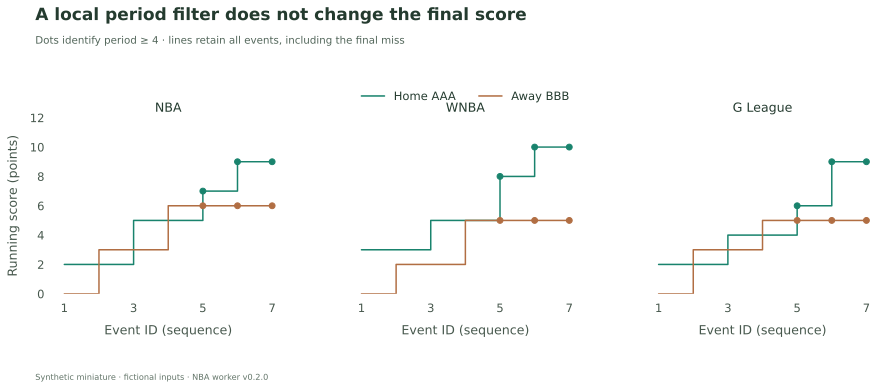

In [9]:
display(event_frame)
fig, axes = plt.subplots(1, 3, figsize=(13, 5.7), sharey=True)
for ax, league in zip(axes, ["nba", "wnba", "gleague"], strict=True):
    rows = event_frame[event_frame.league == league]
    ax.step(rows.action_id, rows.home_score, where="post", color="#19836D", label="Home AAA")
    ax.step(rows.action_id, rows.away_score, where="post", color="#B16E43", label="Away BBB")
    selected = rows[rows.selected_period]
    ax.scatter(selected.action_id, selected.home_score, color="#19836D", s=35, zorder=4)
    ax.scatter(selected.action_id, selected.away_score, color="#B16E43", s=35, zorder=4)
    ax.set_title(LEAGUE_LABELS[league])
    ax.set_xlabel("Event ID (sequence)")
    ax.set_xticks([1, 3, 5, 7])
    ax.set_ylim(0, 12)
axes[0].set_ylabel("Running score (points)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.53, 0.79), ncol=2)
finish(
    fig,
    "A local period filter does not change the final score",
    f"Dots identify period ≥ {MIN_PERIOD} · lines retain all events, including the final miss",
    SOURCE,
    name=f"event-sequence-{MIN_PERIOD}",
)

In [10]:
%%sql selected_points <<
WITH event_points AS (
 SELECT league,team_tricode,
 sum(CASE WHEN shot_result='Made' AND period>={{ MIN_PERIOD }} THEN shot_value ELSE 0 END) AS selected_points,
 sum(CASE WHEN shot_result='Made' THEN shot_value ELSE 0 END) AS all_event_points
 FROM events GROUP BY ALL
), box_points AS (SELECT league,team_tricode,sum(points) AS box_points FROM boxes GROUP BY ALL)
SELECT * FROM box_points JOIN event_points USING(league,team_tricode) ORDER BY league,team_tricode;

,league,team_tricode,box_points,selected_points,all_event_points
0,gleague,AAA,9.0,5.0,9.0
1,gleague,BBB,5.0,0.0,5.0
2,nba,AAA,9.0,4.0,9.0
3,nba,BBB,6.0,0.0,6.0
4,wnba,AAA,10.0,5.0,10.0
5,wnba,BBB,5.0,0.0,5.0


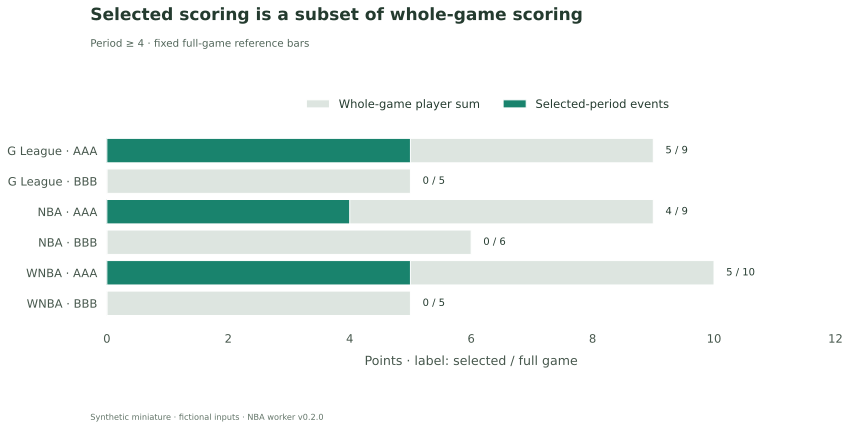

The selected events contain **14** points versus **44** in the unchanged player totals. The final missed shot contributes zero while preserving the previous running score.

In [11]:
display(selected_points)
fig, ax = plt.subplots(figsize=(11.5, 6.3))
y = np.arange(len(selected_points))
ax.barh(y, selected_points.box_points, color="#DDE5E0", label="Whole-game player sum")
ax.barh(y, selected_points.selected_points, color="#19836D", label="Selected-period events")
for i, row in enumerate(selected_points.itertuples()):
    ax.text(row.box_points + 0.2, i, f"{row.selected_points:g} / {row.box_points:g}", va="center", fontsize=10)
ax.set_yticks(y, [f"{LEAGUE_LABELS[r.league]} · {r.team_tricode}" for r in selected_points.itertuples()])
ax.invert_yaxis()
ax.set_xlim(0, 12)
ax.set_xlabel("Points · label: selected / full game")
fig.legend(*ax.get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.55, 0.79), ncol=2)
finish(
    fig,
    "Selected scoring is a subset of whole-game scoring",
    f"Period ≥ {MIN_PERIOD} · fixed full-game reference bars",
    SOURCE,
    name=f"selected-points-{MIN_PERIOD}",
)
prose(
    f"The selected events contain **{int(selected_points.selected_points.sum())}** points versus "
    f"**{int(selected_points.box_points.sum())}** in the unchanged player totals. "
    "The final missed shot contributes zero while preserving the previous running score."
)

### Verify the reconciliation

Check the distinct row grains before comparing totals; retain the last miss and its repeated action number.

In [12]:
%%sql checks <<
SELECT 'three game keys' AS check_name,count(*)=3 AND count(*)=count(DISTINCT(league,game_id)) AS passed FROM boards
UNION ALL SELECT 'unique player-game keys',count(*)=count(DISTINCT(league,game_id,player_id)) FROM boxes
UNION ALL SELECT 'unique event keys',count(*)=count(DISTINCT(league,game_id,action_id)) FROM events
UNION ALL SELECT 'repeated action numbers retained',count(*)>count(DISTINCT(league,game_id,action_number)) FROM events
UNION ALL SELECT 'player sums match scoreboard',NOT EXISTS(SELECT 1 FROM boards b JOIN (SELECT league,game_id,sum(points) FILTER(WHERE is_home) h,sum(points) FILTER(WHERE NOT is_home) a FROM boxes GROUP BY ALL)x USING(league,game_id)WHERE b.home_score<>x.h OR b.away_score<>x.a)
UNION ALL SELECT 'last event matches scoreboard',NOT EXISTS(SELECT 1 FROM boards b JOIN (SELECT * FROM events QUALIFY row_number()OVER(PARTITION BY league,game_id ORDER BY action_id DESC)=1)e USING(league,game_id)WHERE b.home_score<>e.home_score OR b.away_score<>e.away_score)
UNION ALL SELECT 'event points match box sums',NOT EXISTS(SELECT 1 FROM (SELECT league,team_tricode,sum(points) p FROM boxes GROUP BY ALL)b JOIN (SELECT league,team_tricode,sum(CASE WHEN shot_result='Made' THEN shot_value ELSE 0 END)p FROM events GROUP BY ALL)e USING(league,team_tricode) WHERE b.p<>e.p)
UNION ALL SELECT 'no missing running score',NOT EXISTS(SELECT 1 FROM events WHERE home_score IS NULL OR away_score IS NULL)
UNION ALL SELECT 'three distinct league prefixes',count(DISTINCT left(game_id,1))=3 FROM boards;

In [13]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks.to_dict("records")
prose(f"**All {len(checks)} SQL checks passed.** " + source.audit())
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/analysis-02.json").write_text(
    json.dumps(
        {
            "parameters": {"MIN_PERIOD": MIN_PERIOD},
            "game_audit": game_audit.to_dict("records"),
            "event_frame": event_frame.to_dict("records"),
            "selected_points": selected_points.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": source.requests,
        },
        indent=2,
        default=str,
    )
    + "\n"
)

,check_name,passed
0,three game keys,True
1,unique player-game keys,True
2,unique event keys,True
3,repeated action numbers retained,True
4,player sums match scoreboard,True
5,last event matches scoreboard,True
6,event points match box sums,True
7,no missing running score,True
8,three distinct league prefixes,True


**All 9 SQL checks passed.** Exactly 9 approved API requests; each once, all parameters matched.

10248

### Change one thing

Change **MIN_PERIOD 4→1**. The selected contributions should grow to the full player totals, while all scoreboard rows, box-score sums and running-score lines remain identical. Event IDs remain distinct even where action numbers repeat.

In [14]:
assert not con.execute("SELECT * FROM duckdb_secrets()").fetchall()
session.close()
source.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-nba](https://github.com/Query-farm/vgi-nba)